In [6]:
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')
sns.set_style("whitegrid")

In [11]:
import zipfile
import os

zip_path = "/content/online+retail.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/online_retail")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [13]:
import os
for root, dirs, files in os.walk("/content/online_retail"):
    for file in files:
        print(os.path.join(root, file))

/content/online_retail/Online Retail.xlsx


In [14]:
df = pd.read_excel("/content/online_retail/Online Retail.xlsx")

In [ ]:

print("Dataset Shape:", df.shape)
display(df.head())
display(df.tail())
df.info()
display(df.describe())
print(df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())

In [15]:
df.shape

(541909, 8)

In [16]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [18]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [22]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [20]:
df.duplicated().sum()

np.int64(5268)

In [21]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [23]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (536641, 8)


In [24]:
df = df.dropna(subset=['CustomerID'])

#Remove invaild transcations

In [25]:
df = df[df['Quantity'] > 0]
df = df[df['UnitPrice'] > 0]

#Remove cancelled invoices.

In [26]:
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

In [27]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['CustomerID'] = df['CustomerID'].astype(int)

In [28]:
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [29]:
print("Cleaned Dataset Shape:", df.shape)
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

Cleaned Dataset Shape: (392692, 9)
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
dtype: int64
Duplicates: 0


In [30]:
print("Total Customers:", df['CustomerID'].nunique())

Total Customers: 4338


In [31]:
print("Total Transactions:", df['InvoiceNo'].nunique())

Total Transactions: 18532


In [32]:
print("Total Revenue:", df['TotalAmount'].sum())

Total Revenue: 8887208.894000001


In [34]:
print("Average Purchase Value:",df['TotalAmount'].mean())

Average Purchase Value: 22.631499735161402


In [35]:
top_products = (
    df.groupby('Description')['TotalAmount']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products)

,TotalAmount
Description,
"PAPER CRAFT , LITTLE BIRDIE",168469.60
REGENCY CAKESTAND 3 TIER,142264.75
WHITE HANGING HEART T-LIGHT HOLDER,100392.10
JUMBO BAG RED RETROSPOT,85040.54
MEDIUM CERAMIC TOP STORAGE JAR,81416.73
POSTAGE,77803.96
PARTY BUNTING,68785.23
ASSORTED COLOUR BIRD ORNAMENT,56413.03
Manual,53419.93


#Visualize top products

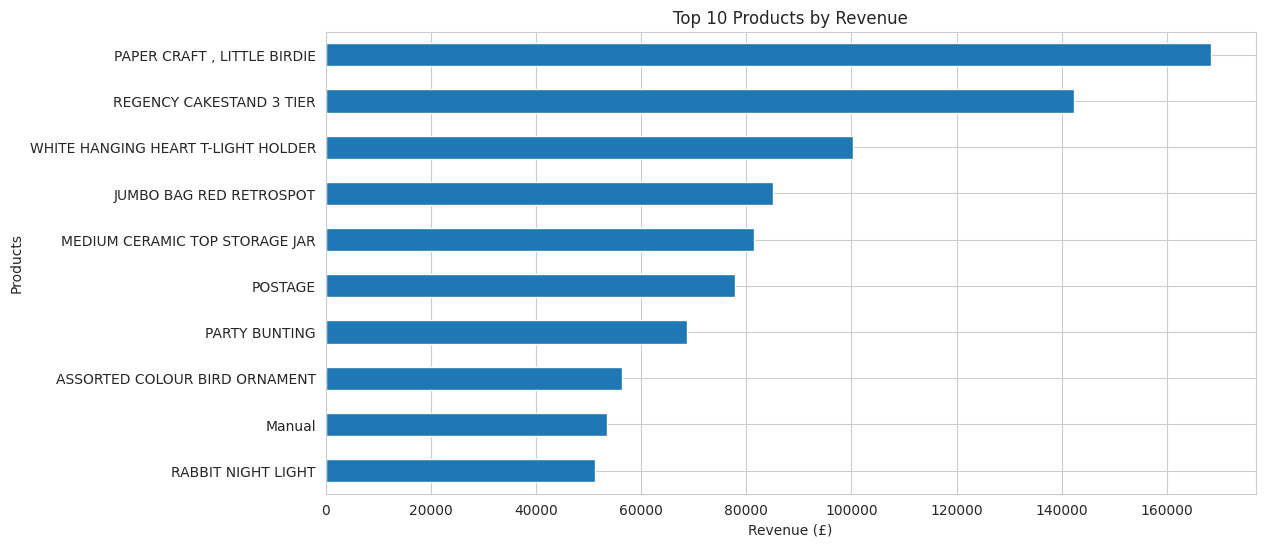

In [36]:
plt.figure(figsize=(12,6))

top_products.sort_values().plot(kind='barh')

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Products")

plt.show()

#RFM Analysis

In [37]:
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print("Reference Date:", reference_date)

Reference Date: 2011-12-10 12:50:00


In [38]:
rfm = df.groupby('CustomerID').agg({

    'InvoiceDate': lambda x: (reference_date - x.max()).days,

    'InvoiceNo': 'nunique',

    'TotalAmount': 'sum'

})

In [39]:
rfm.columns = ['Recency', 'Frequency', 'Monetary']
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [40]:
display(rfm.describe())

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [41]:
rfm['AveragePurchaseValue'] = (
    rfm['Monetary'] / rfm['Frequency']
)

display(rfm.head())

,Recency,Frequency,Monetary,AveragePurchaseValue
CustomerID,,,,
12346,326,1,77183.60,77183.600000
12347,2,7,4310.00,615.714286
12348,75,4,1797.24,449.310000
12349,19,1,1757.55,1757.550000
12350,310,1,334.40,334.400000


In [42]:
rfm['CustomerLifetimeValue'] = rfm['Monetary']
print("Average Customer Purchase Value:",
      rfm['AveragePurchaseValue'].mean())
print("Average Customer Lifetime Value:",
      rfm['CustomerLifetimeValue'].mean())
print("Average Purchase Frequency:",
      rfm['Frequency'].mean())

Average Customer Purchase Value: 417.6457348818341
Average Customer Lifetime Value: 2048.688080682342
Average Purchase Frequency: 4.272014753342554


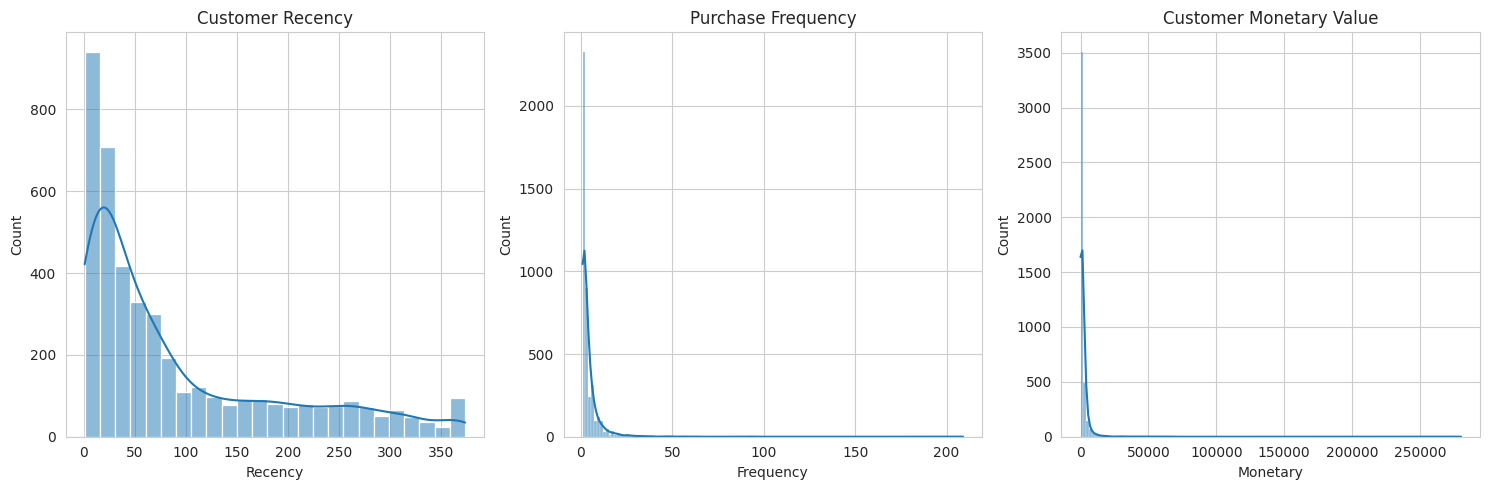

In [44]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
sns.histplot(rfm['Recency'], kde=True)
plt.title("Customer Recency")
plt.subplot(1,3,2)
sns.histplot(rfm['Frequency'], kde=True)
plt.title("Purchase Frequency")
plt.subplot(1,3,3)
sns.histplot(rfm['Monetary'], kde=True)
plt.title("Customer Monetary Value")
plt.tight_layout()
plt.show()

In [45]:
features = rfm[['Recency', 'Frequency', 'Monetary']]
features.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [46]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)
scaled_df = pd.DataFrame(
    scaled_features,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm.index
)
scaled_df.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,2.334574,-0.425097,8.363010
12347,-0.905340,0.354417,0.251699
12348,-0.175360,-0.035340,-0.027988
12349,-0.735345,-0.425097,-0.032406
12350,2.174578,-0.425097,-0.190812


In [47]:
inertia = []
K = range(1, 11)
for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_df)

    inertia.append(kmeans.inertia_)

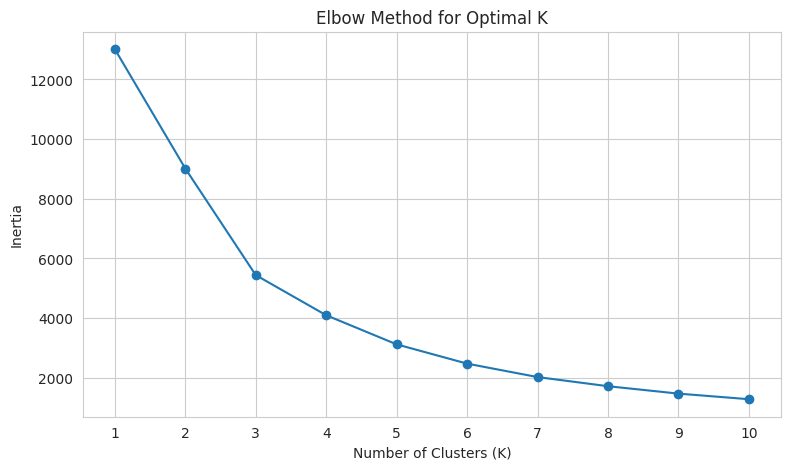

In [49]:
plt.figure(figsize=(9,5))
plt.plot(K, inertia, marker='o')
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(K)
plt.show()

In [50]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(scaled_df)

rfm.head()

,Recency,Frequency,Monetary,AveragePurchaseValue,CustomerLifetimeValue,Cluster
CustomerID,,,,,,
12346,326,1,77183.60,77183.600000,77183.60,3
12347,2,7,4310.00,615.714286,4310.00,0
12348,75,4,1797.24,449.310000,1797.24,0
12349,19,1,1757.55,1757.550000,1757.55,0
12350,310,1,334.40,334.400000,334.40,1


In [51]:
print(rfm['Cluster'].value_counts().sort_index())

Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64


In [52]:
score = silhouette_score(scaled_df, rfm['Cluster'])
print("Silhouette Score:", score)

Silhouette Score: 0.6162275299061803


In [53]:
score = silhouette_score(scaled_df, rfm['Cluster'])
print("Silhouette Score:", score)

Silhouette Score: 0.6162275299061803


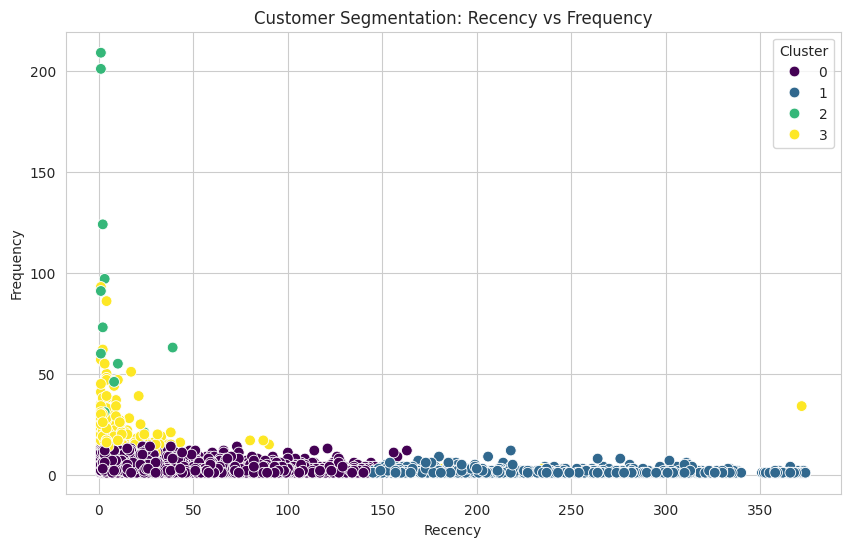

In [54]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Frequency',
    hue='Cluster',
    palette='viridis',
    s=60
)

plt.title("Customer Segmentation: Recency vs Frequency")
plt.show()

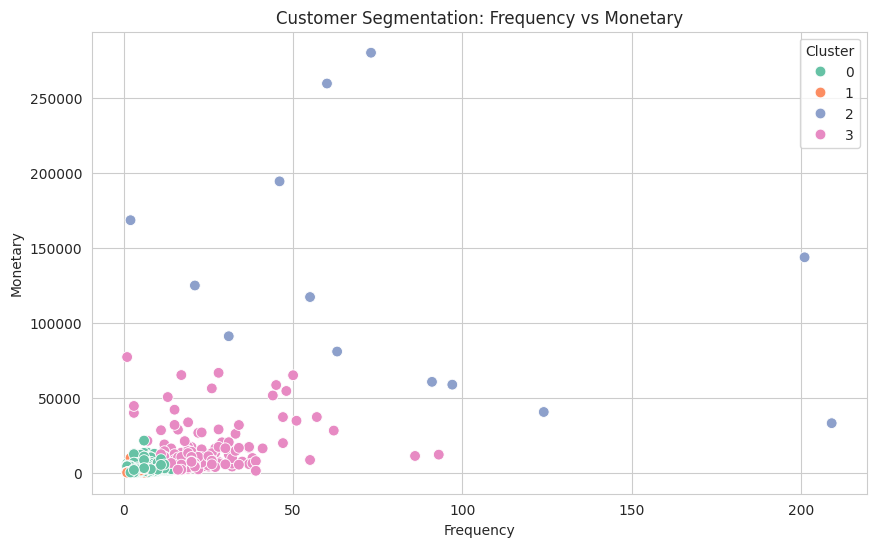

In [55]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='Set2',
    s=60
)

plt.title("Customer Segmentation: Frequency vs Monetary")
plt.show()

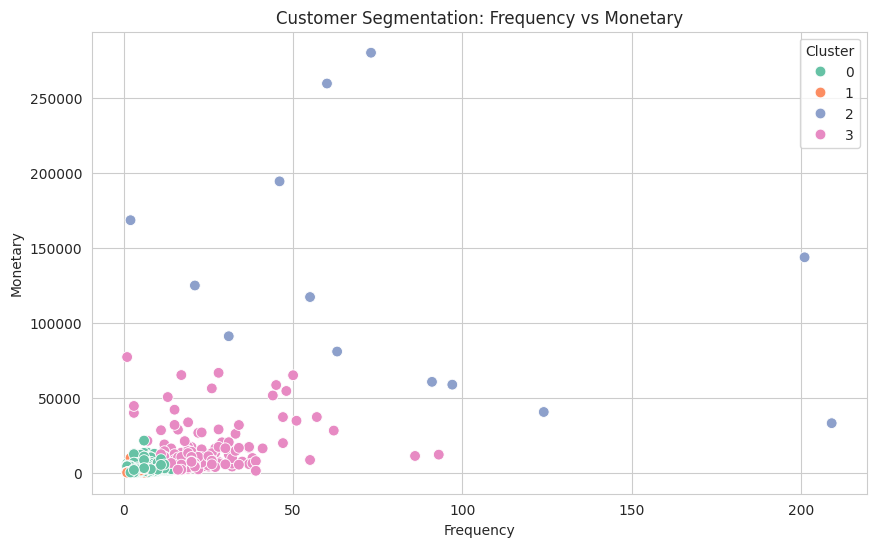

In [56]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='Set2',
    s=60
)

plt.title("Customer Segmentation: Frequency vs Monetary")
plt.show()

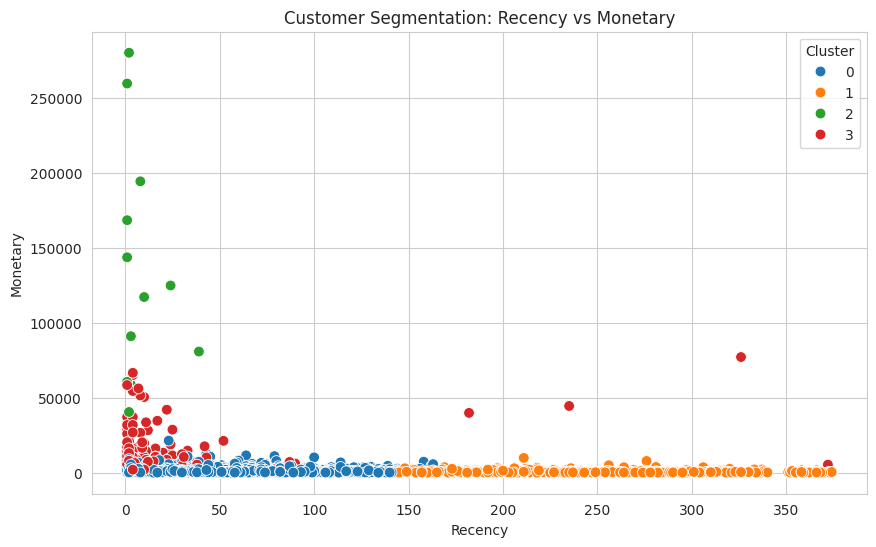

In [57]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='tab10',
    s=60
)

plt.title("Customer Segmentation: Recency vs Monetary")
plt.show()

In [59]:
print(rfm.columns)

Index(['Recency', 'Frequency', 'Monetary', 'AveragePurchaseValue',
       'CustomerLifetimeValue', 'Cluster'],
      dtype='object')


In [60]:
cluster_profile = rfm.groupby('Cluster').agg({

    'Recency': 'mean',

    'Frequency': 'mean',

    'Monetary': 'mean'

})

cluster_profile['CustomerCount'] = rfm.groupby('Cluster').size()

display(cluster_profile.round(2))

,Recency,Frequency,Monetary,CustomerCount
Cluster,,,,
0,43.70,3.68,1353.63,3054
1,248.08,1.55,478.85,1067
2,7.38,82.54,127187.96,13
3,15.50,22.33,12690.50,204


In [61]:
print(rfm['Cluster'].value_counts().sort_index())

Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64


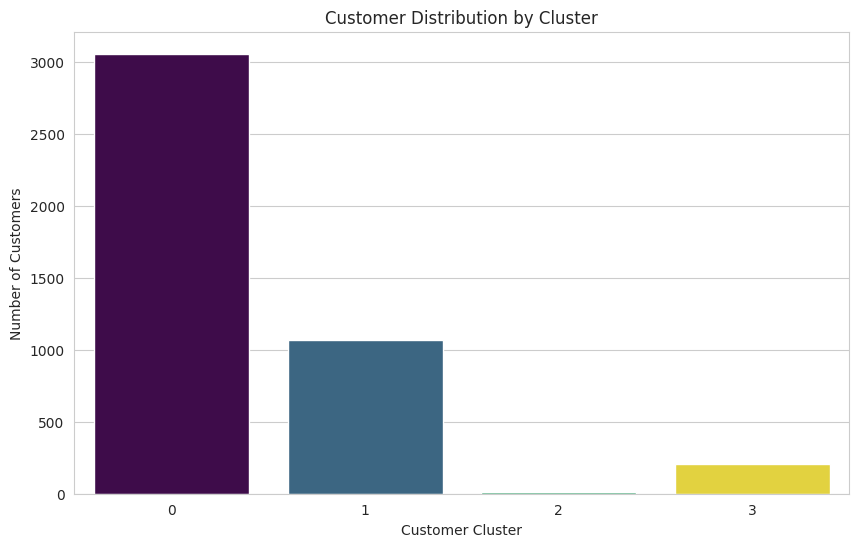

In [62]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=cluster_profile.index,
    y=cluster_profile['CustomerCount'],
    hue=cluster_profile.index,
    palette='viridis',
    legend=False
)

plt.title('Customer Distribution by Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')

plt.show()

In [63]:
display(cluster_profile)

,Recency,Frequency,Monetary,CustomerCount
Cluster,,,,
0,43.702685,3.682711,1353.625312,3054
1,248.075914,1.552015,478.848773,1067
2,7.384615,82.538462,127187.959231,13
3,15.500000,22.333333,12690.500392,204


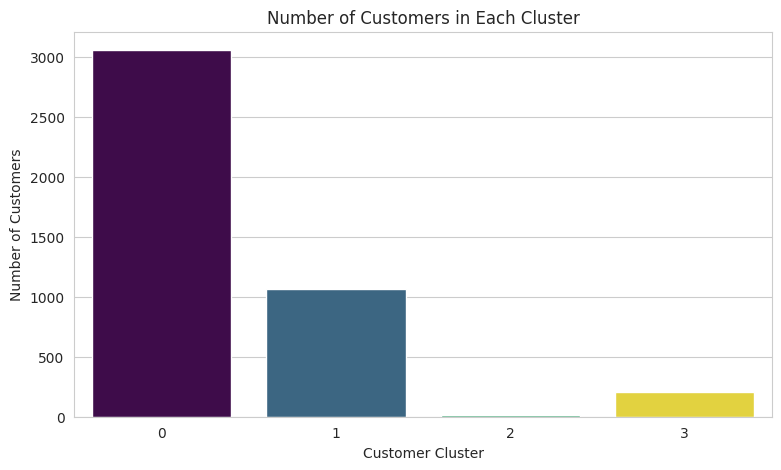

In [65]:
plt.figure(figsize=(9,5))

sns.countplot(
    data=rfm.reset_index(),
    x='Cluster',
    hue='Cluster',
    palette='viridis',
    legend=False
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")

plt.show()

In [66]:
profile = cluster_profile.copy()

# Higher score means better customer value
profile['R_Score'] = profile['Recency'].rank(ascending=True)
profile['F_Score'] = profile['Frequency'].rank(ascending=True)
profile['M_Score'] = profile['Monetary'].rank(ascending=True)

profile['ValueScore'] = (
    profile['R_Score'] +
    profile['F_Score'] +
    profile['M_Score']
)

def assign_segment(row):

    if row['ValueScore'] >= 3 * len(profile) - 2:
        return 'Champions'

    elif row['ValueScore'] >= 2 * len(profile):
        return 'Loyal Customers'

    elif row['R_Score'] == 1:
        return 'At Risk Customers'

    else:
        return 'Potential Customers'

profile['Segment'] = profile.apply(assign_segment, axis=1)

display(profile)

,Recency,Frequency,Monetary,CustomerCount,R_Score,F_Score,M_Score,ValueScore,Segment
Cluster,,,,,,,,,
0,43.702685,3.682711,1353.625312,3054,3.0,2.0,2.0,7.0,Potential Customers
1,248.075914,1.552015,478.848773,1067,4.0,1.0,1.0,6.0,Potential Customers
2,7.384615,82.538462,127187.959231,13,1.0,4.0,4.0,9.0,Loyal Customers
3,15.500000,22.333333,12690.500392,204,2.0,3.0,3.0,8.0,Loyal Customers


In [67]:
segment_mapping = profile['Segment'].to_dict()
rfm['Segment'] = rfm['Cluster'].map(segment_mapping)
display(rfm.head(10))

,Recency,Frequency,Monetary,AveragePurchaseValue,CustomerLifetimeValue,Cluster,Segment
CustomerID,,,,,,,
12346,326,1,77183.60,77183.600000,77183.60,3,Loyal Customers
12347,2,7,4310.00,615.714286,4310.00,0,Potential Customers
12348,75,4,1797.24,449.310000,1797.24,0,Potential Customers
12349,19,1,1757.55,1757.550000,1757.55,0,Potential Customers
12350,310,1,334.40,334.400000,334.40,1,Potential Customers
12352,36,8,2506.04,313.255000,2506.04,0,Potential Customers
12353,204,1,89.00,89.000000,89.00,1,Potential Customers
12354,232,1,1079.40,1079.400000,1079.40,1,Potential Customers
12355,214,1,459.40,459.400000,459.40,1,Potential Customers


In [68]:
for cluster, row in profile.iterrows():

    print("\nCluster:", cluster)
    print("Segment:", row['Segment'])
    print("Average Recency:", round(row['Recency'], 2))
    print("Average Frequency:", round(row['Frequency'], 2))
    print("Average Monetary:", round(row['Monetary'], 2))
    print("Customer Count:", int(row['CustomerCount']))

    if row['Segment'] == 'Champions':
        print("Recommendation: VIP rewards and exclusive offers.")

    elif row['Segment'] == 'Loyal Customers':
        print("Recommendation: Loyalty points and membership rewards.")

    elif row['Segment'] == 'At Risk Customers':
        print("Recommendation: Win-back campaigns and personalized discounts.")

    else:
        print("Recommendation: Welcome offers and product recommendations.")


Cluster: 0
Segment: Potential Customers
Average Recency: 43.7
Average Frequency: 3.68
Average Monetary: 1353.63
Customer Count: 3054
Recommendation: Welcome offers and product recommendations.

Cluster: 1
Segment: Potential Customers
Average Recency: 248.08
Average Frequency: 1.55
Average Monetary: 478.85
Customer Count: 1067
Recommendation: Welcome offers and product recommendations.

Cluster: 2
Segment: Loyal Customers
Average Recency: 7.38
Average Frequency: 82.54
Average Monetary: 127187.96
Customer Count: 13
Recommendation: Loyalty points and membership rewards.

Cluster: 3
Segment: Loyal Customers
Average Recency: 15.5
Average Frequency: 22.33
Average Monetary: 12690.5
Customer Count: 204
Recommendation: Loyalty points and membership rewards.


In [69]:
final_data = rfm.reset_index()

final_data.to_csv(
    'OIBSIP_Customer_Segmentation_Results.csv',
    index=False
)

print("Customer segmentation exported successfully!")

Customer segmentation exported successfully!


In [71]:
from google.colab import files

files.download('OIBSIP_Customer_Segmentation_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Customer Segmentation Analysis – Project Report

## Objective
To segment e-commerce customers based on their purchasing behaviour using RFM analysis and K-Means clustering.

## Tools Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Google Colab

## Methodology
1. Dataset collection and inspection.
2. Data cleaning and preprocessing.
3. Recency, Frequency and Monetary calculation.
4. Feature scaling using StandardScaler.
5. Optimal cluster selection using the Elbow Method.
6. Customer segmentation using K-Means.
7. Cluster visualization and customer profiling.

## Key Findings
- Total customers: [Insert actual value]
- Optimal number of clusters: [Insert selected K]
- Silhouette score: [Insert actual score]
- Highest-value customer segment: [Insert actual segment]
- Largest customer segment: [Insert actual segment]

## Business Recommendations
- Offer exclusive rewards to high-value customers.
- Develop loyalty programs for frequent purchasers.
- Run re-engagement campaigns for inactive customers.
- Provide personalized offers to potential customers.

## Conclusion
K-Means clustering helped identify customer groups based on purchasing behaviour. The segmentation results can support targeted marketing, customer retention and improved business decision-making.